# Checkpoint 3: Xử Lý Mất Cân Bằng Lớp Bằng Focal Loss (Focal Loss for Hard Example Mining)

Nghiên cứu: Nâng cao hiệu năng mô hình phát hiện phát ngôn thù ghét trên mạng xã hội tiếng Việt (ViHSD).

Mục tiêu kỹ thuật của Checkpoint 3:
1. Giải quyết triệt để hiện tượng mất cân bằng lớp nghiêm trọng trong tập dữ liệu ViHSD: CLEAN (~82.7%), OFFENSIVE (~6.7%), HATE (~10.6%).
2. Khắc phục hạn chế của hàm mất mát Cross-Entropy tiêu chuẩn: số lượng áp đảo của các mẫu CLEAN dễ phân loại (p_t tiến gần 1.0) tích lũy gradient lấn át toàn bộ quá trình cập nhật trọng số, khiến mô hình thiên lệch về lớp đa số và bỏ sót các mẫu thù ghét khó phân loại.
3. Tích hợp hàm mất mát Focal Loss đa lớp (Lin et al., 2017) với cơ chế điều chế mẫu khó (Hard Example Mining):
   FL(p_t) = -(1 - p_t)^gamma * log(p_t)
   Hệ số điều chế (1 - p_t)^gamma tự động triệt tiêu gradient của các mẫu dễ phân loại và tập trung tối ưu hóa vào các mẫu khó thuộc hai lớp thiểu số (OFFENSIVE và HATE).
4. Khảo sát độc lập tác động của tham số tập trung gamma (thiết lập gamma = 1.5) khi cố định alpha = 1.0 nhằm cô lập ảnh hưởng của cơ chế điều chế động trước khi kết hợp trọng số lớp tĩnh ở các checkpoint tiếp theo.
5. Kế thừa toàn bộ chiến lược huấn luyện tối ưu đã thiết lập từ Checkpoint 2: mở rộng ngữ cảnh max_length = 256, phân tầng tốc độ học (Differential Learning Rates: Backbone 2e-5, Classification Head 1e-4), lịch trình Cosine Annealing kèm Warmup, và lưu trữ trọng số tối ưu nhất theo eval_macro_f1 trên tập dev với Early Stopping.
6. Phân tích định lượng sự dịch chuyển độ nhạy (Recall) của các lớp thiểu số, chứng minh sự suy giảm rõ rệt của các trường hợp phân loại sai nhãn OFFENSIVE và HATE thành CLEAN.

Ghi chú: Toàn bộ mã nguồn tiền xử lý, cấu trúc Dataset, định nghĩa lớp FocalLoss, lớp tùy biến FocalLossTrainer, các hàm đánh giá và trực quan hóa được tích hợp trực tiếp 100% trong notebook nhằm đảm bảo tính độc lập hoàn toàn khi thực thi trên Google Colab.

In [1]:
import os
import sys

# Thiết lập môi trường làm việc và kết nối Google Drive trên Google Colab
try:
    from google.colab import drive
    drive.mount('/content/drive')
    project_dir = '/content/drive/MyDrive/NLP_PhoBert_ViHSD'
except ImportError:
    project_dir = os.path.abspath('..')

checkpoints_dir = os.path.join(project_dir, 'checkpoints', 'checkpoint03_15')
outputs_dir = os.path.join(project_dir, 'outputs', 'checkpoint03_15')

os.makedirs(checkpoints_dir, exist_ok=True)
os.makedirs(outputs_dir, exist_ok=True)

print(f'Thư mục dự án: {project_dir}')
print(f'Thư mục lưu checkpoint: {checkpoints_dir}')
print(f'Thư mục lưu kết quả: {outputs_dir}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Thư mục dự án: /content/drive/MyDrive/NLP_PhoBert_ViHSD
Thư mục lưu checkpoint: /content/drive/MyDrive/NLP_PhoBert_ViHSD/checkpoints/checkpoint03_15
Thư mục lưu kết quả: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint03_15


In [2]:
# Cài đặt các thư viện cần thiết trên môi trường Google Colab
!pip install -q pyvi transformers accelerate scikit-learn seaborn matplotlib pandas numpy torch

In [3]:
# Thiết lập hạt giống ngẫu nhiên cố định để đảm bảo tính tái lập thực nghiệm
random_seed = 42

import os
import random
import numpy as np
import torch

random.seed(random_seed)
np.random.seed(random_seed)
torch.manual_seed(random_seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(random_seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

print(f'Hạt giống ngẫu nhiên đã được cố định: {random_seed}')
print(f'Thiết bị tính toán: {"CUDA (GPU)" if torch.cuda.is_available() else "CPU"}')

Hạt giống ngẫu nhiên đã được cố định: 42
Thiết bị tính toán: CUDA (GPU)


## 1. Nạp Tập Dữ Liệu Thô và Kiểm Tra Trước Xử Lý (Pre-pipeline Verification)

Kiểm tra tính toàn vẹn của ba tập dữ liệu chuẩn: `train.csv`, `dev.csv` và `test.csv`. Đảm bảo số lượng mẫu khớp tuyệt đối với nghiên cứu cơ sở của Luu et al. (2021) và phân tích sự phân bổ mất cân bằng nghiêm trọng giữa các nhãn.

In [4]:
# Cấu hình đường dẫn tập dữ liệu
data_dir = 'data' if os.path.exists('data/train.csv') else os.path.join(project_dir, 'data')
train_path = os.path.join(data_dir, 'train.csv')
dev_path = os.path.join(data_dir, 'dev.csv')
test_path = os.path.join(data_dir, 'test.csv')

import pandas as pd

print(f'Đọc tập Train từ: {train_path}')
print(f'Đọc tập Dev từ:   {dev_path}')
print(f'Đọc tập Test từ:  {test_path}')

train_raw = pd.read_csv(train_path)
dev_raw = pd.read_csv(dev_path)
test_raw = pd.read_csv(test_path)

# Kiểm tra toàn vẹn số lượng mẫu và giá trị thiếu trước khi đưa vào pipeline
assert len(train_raw) == 24048, f'Số lượng mẫu train không khớp: {len(train_raw)}'
assert len(dev_raw) == 2672, f'Số lượng mẫu dev không khớp: {len(dev_raw)}'
assert len(test_raw) == 6680, f'Số lượng mẫu test không khớp: {len(test_raw)}'

print('Kiểm tra tập dữ liệu thô trước xử lý:')
print(f'- Train: {len(train_raw)} mẫu, giá trị thiếu free_text: {train_raw["free_text"].isna().sum()}')
print(f'- Dev:   {len(dev_raw)} mẫu, giá trị thiếu free_text: {dev_raw["free_text"].isna().sum()}')
print(f'- Test:  {len(test_raw)} mẫu, giá trị thiếu free_text: {test_raw["free_text"].isna().sum()}')

# Thống kê phân bổ nhãn trên tập huấn luyện
train_dist = train_raw['label_id'].value_counts().sort_index()
print('\nPhân bổ nhãn trên tập huấn luyện:')
class_labels = {0: 'CLEAN', 1: 'OFFENSIVE', 2: 'HATE'}
for label_id, count in train_dist.items():
    pct = (count / len(train_raw)) * 100
    print(f'  Lớp {label_id} ({class_labels.get(label_id, "UNKNOWN")}): {count:5d} mẫu ({pct:5.2f}%)')

Đọc tập Train từ: data/train.csv
Đọc tập Dev từ:   data/dev.csv
Đọc tập Test từ:  data/test.csv
Kiểm tra tập dữ liệu thô trước xử lý:
- Train: 24048 mẫu, giá trị thiếu free_text: 2
- Dev:   2672 mẫu, giá trị thiếu free_text: 0
- Test:  6680 mẫu, giá trị thiếu free_text: 0

Phân bổ nhãn trên tập huấn luyện:
  Lớp 0 (CLEAN): 19886 mẫu (82.69%)
  Lớp 1 (OFFENSIVE):  1606 mẫu ( 6.68%)
  Lớp 2 (HATE):  2556 mẫu (10.63%)


## 2. Định Nghĩa Trực Tiếp Lớp Tiền Xử Lý ViHSDPreprocessor

Lớp `ViHSDPreprocessor` được tích hợp trực tiếp, thực thi quy trình chuẩn hóa văn bản mạng xã hội tiếng Việt:
1. Làm sạch URL, Email, thẻ HTML và chuẩn hóa khoảng trắng thừa.
2. Xử lý biểu tượng cảm xúc (Emoji) 2 pha: đệm khoảng trắng bảo vệ từ tố và ánh xạ sang từ vựng tiếng Việt tương ứng.
3. Chuẩn hóa teencode, từ lóng và biến thể né kiểm duyệt bằng ranh giới từ (Word Boundary Protection).
4. Thu gọn ký tự lặp kéo dài (Lengthening Reduction) về 1 ký tự duy nhất.
5. Phân đoạn từ tiếng Việt tự động bằng thư viện `PyVi` theo chuẩn đầu vào PhoBERT.
6. Tuyệt đối không loại bỏ từ dừng, bảo tồn toàn bộ đại từ nhân xưng (`mày`, `tao`, `nó`, `thằng`, `con`) và từ phủ định (`không`, `chẳng`, `chả`).

In [5]:
import os
import re
import pandas as pd
import numpy as np

try:
    from pyvi import ViTokenizer
except ImportError:
    ViTokenizer = None


class ViHSDPreprocessor:
    """Bộ tiền xử lý và chuẩn hóa văn bản cho bài toán phát hiện phát ngôn thù ghét (ViHSD).

    Quy trình xử lý bao gồm:
    1. Làm sạch URL, Email, thẻ HTML và chuẩn hóa khoảng trắng.
    2. Bảo tồn và ánh xạ sắc thái cảm xúc (Emoji) qua quy trình 2 pha dựa vào từ điển bên ngoài.
    3. Chuẩn hóa teencode, tiếng lóng và biến thể né kiểm duyệt qua từ điển bên ngoài.
    4. Thu gọn ký tự lặp kéo dài (Lengthening Reduction).
    5. Bảo tồn nguyên vẹn từ dừng, đại từ nhân xưng và từ phủ định.
    6. Phân đoạn từ tiếng Việt sử dụng PyVi.
    """

    # Khởi tạo đối tượng tiền xử lý với các đường dẫn từ điển teencode và emoji
    def __init__(self, teencode_path='data/teencode.csv', emoji_path='data/emojis.csv'):
        self.teencode_dict = self.load_teencode(teencode_path)
        self.emoji_dict = self.load_emoji_mapping(emoji_path)
        self._init_regex_patterns()

    # Biên dịch trước toàn bộ biểu thức chính quy nhằm tối ưu tốc độ xử lý trên tập dữ liệu lớn
    def _init_regex_patterns(self):
        self.url_pattern = re.compile(r'https?://\S+|www\.\S+', re.IGNORECASE)
        self.email_pattern = re.compile(r'\S+@\S+', re.IGNORECASE)
        self.html_pattern = re.compile(r'<.*?>')
        self.whitespace_pattern = re.compile(r'\s+')

        # Nhận diện ký tự chữ cái lặp lại từ 3 lần trở lên bao gồm cả bảng chữ cái tiếng Việt
        self.lengthening_pattern = re.compile(
            r'([a-zA-ZàáảãạăằắẳẵặâầấẩẫậèéẻẽẹêềếểễệìíỉĩịòóỏõọôồốổỗộơờớởỡợùúủũụưừứửữựỳýỷỹỵđĐ])\1{2,}',
            re.IGNORECASE,
        )

        # Biểu thức đệm khoảng trắng bao quanh emoji để ngăn lỗi dính từ khi tách từ bằng PyVi
        self.emoji_padding_pattern = re.compile(
            r'(\s*)([\U00010000-\U0010ffff\u2600-\u27ff])(\s*)'
        )

        # Mẫu khớp từ điển emoji theo thứ tự độ dài giảm dần
        sorted_emojis = sorted(self.emoji_dict.keys(), key=len, reverse=True)
        self.emoji_replace_pattern = re.compile(
            '|'.join(re.escape(k) for k in sorted_emojis)
        )

        # Mẫu khớp teencode kết hợp biên giới từ để tránh thay thế nhầm từ tố hợp lệ
        sorted_teencode = sorted(self.teencode_dict.keys(), key=len, reverse=True)
        teencode_patterns = []
        for k in sorted_teencode:
            escaped = re.escape(k)
            left = r'(?<!\w)' if re.match(r'^\w', k) else ''
            right = r'(?!\w)' if re.search(r'\w$', k) else ''
            teencode_patterns.append(f'{left}{escaped}{right}')
        self.teencode_pattern = re.compile(
            '|'.join(teencode_patterns), re.IGNORECASE
        )

    # Đọc từ điển teencode và từ lóng từ tệp CSV thành từ điển ánh xạ
    def load_teencode(self, path):
        df = pd.read_csv(path)
        return dict(
            zip(
                df['teencode'].astype(str).str.strip().str.lower(),
                df['replacement'].astype(str).str.strip().str.lower(),
            )
        )

    # Đọc bảng ánh xạ biểu tượng cảm xúc (emoji) từ tệp CSV thành từ điển thay thế
    def load_emoji_mapping(self, path):
        df = pd.read_csv(path)
        return dict(
            zip(
                df['emoji'].astype(str).str.strip(),
                df['replacement'].astype(str).str.strip(),
            )
        )

    # Loại bỏ đường dẫn URL, địa chỉ email, thẻ HTML và khoảng trắng thừa
    def clean_special_characters(self, text):
        text = self.url_pattern.sub(' ', text)
        text = self.email_pattern.sub(' ', text)
        text = self.html_pattern.sub(' ', text)
        return self.whitespace_pattern.sub(' ', text).strip()

    # Xử lý emoji 2 pha: đệm khoảng trắng bảo vệ từ tố rồi ánh xạ ngữ nghĩa sang PhoBERT
    def pad_and_map_emojis(self, text):
        text = self.emoji_padding_pattern.sub(r' \2 ', text)
        text = self.emoji_replace_pattern.sub(
            lambda m: f' {self.emoji_dict[m.group(0)]} ', text
        )
        return self.whitespace_pattern.sub(' ', text).strip()

    # Chuẩn hóa từ viết tắt và tiếng lóng dựa trên biên giới từ
    def normalize_teencode(self, text):
        return self.teencode_pattern.sub(
            lambda m: self.teencode_dict.get(m.group(0).lower(), m.group(0)), text
        )

    # Thu gọn các ký tự chữ cái lặp lại liên tiếp từ 3 lần trở lên về 1 ký tự duy nhất
    def reduce_lengthening(self, text):
        return self.lengthening_pattern.sub(r'\1', text)

    # Phân đoạn từ tiếng Việt tự động bằng thư viện PyVi theo quy chuẩn PhoBERT
    def segment_words(self, text):
        if ViTokenizer is None:
            raise ImportError(
                'Thư viện pyvi chưa được cài đặt. Vui lòng cài đặt qua lệnh: pip install pyvi'
            )
        return ViTokenizer.tokenize(text)

    # Thực hiện quy trình tiền xử lý hoàn chỉnh cho một đoạn văn bản theo đúng thứ tự logic
    def transform_text(self, text, lowercased=False):
        if not isinstance(text, str):
            text = str(text) if text is not None else ''

        if not text.strip():
            return ''

        # Thực hiện tuần tự: Làm sạch -> Emoji -> Teencode -> Thu gọn ký tự -> Tách từ PyVi
        text = self.clean_special_characters(text)
        text = self.pad_and_map_emojis(text)
        text = self.normalize_teencode(text)
        text = self.reduce_lengthening(text)

        # Bảo tồn toàn bộ đại từ nhân xưng và từ phủ định (tuyệt đối không lọc từ dừng)
        if text.strip():
            text = self.segment_words(text)

        if lowercased:
            text = text.lower()

        return self.whitespace_pattern.sub(' ', text).strip()

    # Áp dụng chuẩn hóa trên toàn bộ DataFrame, loại bỏ dòng rỗng/thiếu và trả về mảng đặc trưng X và nhãn y
    def transform_dataset(self, df, text_col='free_text', label_col='label_id', lowercased=False):
        df_clean = df.dropna(subset=[text_col, label_col]).copy()
        df_clean[label_col] = df_clean[label_col].astype(int)

        transformed_texts = []
        valid_indices = []

        for idx, row in df_clean.iterrows():
            cleaned_text = self.transform_text(row[text_col], lowercased=lowercased)
            if cleaned_text:
                transformed_texts.append(cleaned_text)
                valid_indices.append(idx)

        filtered_df = df_clean.loc[valid_indices].copy()
        X = transformed_texts
        y = filtered_df[label_col].to_numpy()

        return X, y

## 3. Khởi Tạo Bộ Tiền Xử Lý và Chuẩn Hóa Dữ Liệu

Áp dụng quy trình tiền xử lý đồng bộ trên cả ba tập `train.csv`, `dev.csv` và `test.csv`. Thực hiện các phép kiểm tra (Assertion Checks) nghiêm ngặt sau tiền xử lý để loại trừ hoàn toàn chuỗi rỗng và đảm bảo tính nhất quán giữa dữ liệu văn bản và mảng nhãn.

In [6]:
# Cấu hình đường dẫn từ điển chuẩn hóa
teencode_path = os.path.join(data_dir, 'teencode.csv')
emoji_path = os.path.join(data_dir, 'emojis.csv')

print(f'Nạp từ điển teencode từ: {teencode_path}')
print(f'Nạp từ điển emoji từ:    {emoji_path}')

# Khởi tạo bộ tiền xử lý với từ điển ngoài
preprocessor = ViHSDPreprocessor(teencode_path=teencode_path, emoji_path=emoji_path)

# Thực thi tiền xử lý trên toàn bộ tập dữ liệu
text_column = 'free_text'
label_column = 'label_id'
preserve_casing = False

train_X, train_y = preprocessor.transform_dataset(
    train_raw, text_col=text_column, label_col=label_column, lowercased=preserve_casing
)
dev_X, dev_y = preprocessor.transform_dataset(
    dev_raw, text_col=text_column, label_col=label_column, lowercased=preserve_casing
)
test_X, test_y = preprocessor.transform_dataset(
    test_raw, text_col=text_column, label_col=label_column, lowercased=preserve_casing
)

# Kiểm tra tính toàn vẹn sau xử lý (Post-pipeline Verification)
assert len(train_X) == len(train_y), 'Số lượng đặc trưng và nhãn train không khớp'
assert len(dev_X) == len(dev_y), 'Số lượng đặc trưng và nhãn dev không khớp'
assert len(test_X) == len(test_y), 'Số lượng đặc trưng và nhãn test không khớp'
assert sum(len(x.strip()) == 0 for x in train_X) == 0, 'Tồn tại chuỗi rỗng trong train_X'
assert set(np.unique(train_y)).issubset({0, 1, 2}), 'Tồn tại nhãn không hợp lệ trong train_y'

print('Kết quả tiền xử lý dữ liệu thành công:')
print(f'- Tập Train hợp lệ: {len(train_X)} / {len(train_raw)}')
print(f'- Tập Dev hợp lệ:   {len(dev_X)} / {len(dev_raw)}')
print(f'- Tập Test hợp lệ:  {len(test_X)} / {len(test_raw)}')

Nạp từ điển teencode từ: data/teencode.csv
Nạp từ điển emoji từ:    data/emojis.csv
Kết quả tiền xử lý dữ liệu thành công:
- Tập Train hợp lệ: 24046 / 24048
- Tập Dev hợp lệ:   2671 / 2672
- Tập Test hợp lệ:  6680 / 6680


## 4. Định Nghĩa Lớp BuildDataset và Mã Hóa Với Độ Dài Mở Rộng (max_length = 256)

Kế thừa thiết lập tối ưu từ Checkpoint 2:
- Mở rộng độ dài chuỗi tối đa lên `max_length = 256` token (tận dụng tối đa giới hạn vị trí nhúng `max_position_embeddings = 256` của kiến trúc `vinai/phobert-base`).
- Bao phủ trọn vẹn ngữ cảnh của các bình luận dài trên mạng xã hội, ngăn ngừa hiện tượng cắt cụt các từ khóa thù ghét hoặc đối tượng công kích thường nằm ở cuối câu.
- Sử dụng `AutoTokenizer.from_pretrained('vinai/phobert-base', use_fast=False)`.

In [7]:
# Cấu hình tham số mã hóa chuỗi mở rộng cho Checkpoint 3
pretrained_model_name = 'vinai/phobert-base'
max_seq_length = 256

import torch
from transformers import AutoTokenizer


class BuildDataset(torch.utils.data.Dataset):
    """Lớp quản lý và đóng gói tập dữ liệu tương thích với Hugging Face Trainer và mô hình PhoBERT."""

    # Khởi tạo đối tượng tập dữ liệu với đặc trưng token hóa và mảng nhãn tương ứng
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    # Trích xuất mẫu dữ liệu tại chỉ mục xác định và đóng gói thành PyTorch Tensor
    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

    # Trả về tổng số lượng mẫu quan sát có trong tập dữ liệu
    def __len__(self):
        return len(self.labels)


print(f'Khởi tạo Tokenizer: {pretrained_model_name} (use_fast=False, max_length={max_seq_length})')
tokenizer = AutoTokenizer.from_pretrained(pretrained_model_name, use_fast=False)

train_encodings = tokenizer(train_X, truncation=True, padding=True, max_length=max_seq_length)
dev_encodings = tokenizer(dev_X, truncation=True, padding=True, max_length=max_seq_length)
test_encodings = tokenizer(test_X, truncation=True, padding=True, max_length=max_seq_length)

train_dataset = BuildDataset(train_encodings, train_y)
dev_dataset = BuildDataset(dev_encodings, dev_y)
test_dataset = BuildDataset(test_encodings, test_y)

print(f'Kích thước tập train sau mã hóa: {len(train_dataset)}')
print(f'Kích thước tập dev sau mã hóa:   {len(dev_dataset)}')
print(f'Kích thước tập test sau mã hóa:  {len(test_dataset)}')

Khởi tạo Tokenizer: vinai/phobert-base (use_fast=False, max_length=256)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Kích thước tập train sau mã hóa: 24046
Kích thước tập dev sau mã hóa:   2671
Kích thước tập test sau mã hóa:  6680


## 5. Định Nghĩa Hàm Mất Mát Focal Loss và Lớp Trainer Tùy Biến (Focal Loss & Custom Trainer)

### 5.1. Cơ sở toán học của Focal Loss
Trong bài toán phân loại đa lớp, hàm mất mát Cross-Entropy tiêu chuẩn cho mẫu $i$ có nhãn thực tế $y_i$ là:
$$\mathcal{L}_{CE}(p_t) = -\log(p_t)$$
Trong đó $p_t = \frac{\exp(z_{y_i})}{\sum_{c=0}^2 \exp(z_c)}$ là xác suất dự đoán của nhãn đúng.

Focal Loss bổ sung hệ số điều chế $(1 - p_t)^\gamma$ nhằm triệt tiêu gradient của các mẫu dễ:
$$\mathcal{L}_{FL}(p_t) = -(1 - p_t)^\gamma \log(p_t)$$
- **Mẫu dễ phân loại ($p_t \to 1$):** Hệ số $(1 - p_t)^\gamma \to 0$, giá trị tổn thất bị suy giảm đáng kể, triệt tiêu gradient lấn át từ các mẫu CLEAN.
- **Mẫu khó phân loại ($p_t \to 0$):** Hệ số $(1 - p_t)^\gamma \approx 1$, giá trị tổn thất và gradient được bảo toàn, tập trung tối ưu hóa các mẫu OFFENSIVE và HATE.
- $\gamma \ge 0$ là tham số tập trung (Focusing Parameter). Khi $\gamma = 0$, Focal Loss tương đương tuyệt đối với Cross-Entropy.
- Trong Checkpoint 3, thiết lập $\alpha = 1$ để cô lập tác động của cơ chế điều chế mẫu khó mà không bị chi phối bởi vector trọng số lớp tĩnh.

### 5.2. Tính toán ổn định số học trong PyTorch
Để tránh lỗi tràn số (numerical underflow/overflow), giá trị $p_t$ và $-\log(p_t)$ được tính toán thông qua `F.cross_entropy(logits, targets, reduction='none')` vốn tận dụng thủ thuật log-sum-exp ổn định:
$$p_t = \exp(-\mathcal{L}_{CE})$$
$$\mathcal{L}_{FL} = (1 - p_t)^\gamma \cdot \mathcal{L}_{CE}$$

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import Trainer


# Định nghĩa hàm mất mát Focal Loss đa lớp với cơ chế điều chế mẫu khó
class FocalLoss(nn.Module):
    """Hàm mất mát Focal Loss đa lớp triệt tiêu gradient từ mẫu dễ phân loại và tập trung vào mẫu khó.

    Công thức toán học:
        FL(p_t) = -alpha_t * (1 - p_t)^gamma * log(p_t)

    Trong đó:
        - p_t là xác suất dự đoán của mô hình cho nhãn thực tế.
        - (1 - p_t)^gamma là hệ số điều chế (Modulating Factor).
        - gamma là tham số tập trung (Focusing Parameter): khi gamma = 0, hàm trở về Cross-Entropy tiêu chuẩn.
        - alpha_t là hệ số cân bằng nhãn (được thiết lập None trong Checkpoint 3 để cô lập tác động của gamma).
    """

    # Khởi tạo hàm mất mát với tham số tập trung gamma, hệ số trọng số alpha và cơ chế reduction
    def __init__(self, gamma=1.5, alpha=None, reduction='mean'):
        super().__init__()
        self.gamma = gamma
        self.alpha = alpha
        self.reduction = reduction

    # Lan truyền xuôi tính toán giá trị tổn thất Focal Loss ổn định số học
    def forward(self, logits, targets):
        """Tính toán tổn thất Focal Loss trên mini-batch với độ ổn định số học cao.

        Tham số:
            logits: Tensor kích thước (batch_size, num_classes) chứa logits chưa qua softmax.
            targets: Tensor kích thước (batch_size,) chứa nhãn nguyên thực tế.

        Trả về:
            Tensor tổn thất tương ứng theo cơ chế reduction đã cấu hình.
        """
        # Tính Cross-Entropy từng mẫu để tận dụng tính ổn định số học của log-sum-exp
        ce_loss = F.cross_entropy(logits, targets, reduction='none')

        # Xác suất dự đoán của nhãn thực tế: p_t = exp(-ce_loss)
        pt = torch.exp(-ce_loss)

        # Hệ số điều chế triệt tiêu mẫu dễ: (1 - p_t)^gamma
        modulating_factor = (1.0 - pt) ** self.gamma
        focal_loss = modulating_factor * ce_loss

        # Áp dụng trọng số nhãn alpha nếu được cấu hình
        if self.alpha is not None:
            if isinstance(self.alpha, torch.Tensor):
                alpha_t = self.alpha.to(logits.device)[targets]
                focal_loss = alpha_t * focal_loss
            else:
                focal_loss = self.alpha * focal_loss

        if self.reduction == 'mean':
            return focal_loss.mean()
        elif self.reduction == 'sum':
            return focal_loss.sum()
        return focal_loss


# Lớp Trainer tùy biến ghi đè phương thức compute_loss để áp dụng Focal Loss
class FocalLossTrainer(Trainer):
    """Lớp Trainer tùy biến tích hợp hàm mất mát Focal Loss cho quá trình huấn luyện Hugging Face."""

    # Khởi tạo Trainer với tham số gamma và alpha cho Focal Loss
    def __init__(self, *args, focal_gamma=1.5, focal_alpha=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.focal_gamma = focal_gamma
        self.focal_alpha = focal_alpha
        self.loss_fn = FocalLoss(gamma=focal_gamma, alpha=focal_alpha, reduction='mean')

    # Ghi đè phương thức tính toán tổn thất của Trainer bằng Focal Loss
    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None, **kwargs):
        """Tính toán tổn thất trên batch sử dụng hàm mất mát Focal Loss."""
        labels = inputs.get('labels')
        outputs = model(**inputs)
        logits = outputs.get('logits')

        loss = self.loss_fn(logits, labels)
        return (loss, outputs) if return_outputs else loss


# Kiểm tra tính ổn định số học và tính tương đương toán học khi gamma = 0
dummy_logits = torch.tensor([[2.5, 0.1, 0.2], [0.3, 3.0, 0.4], [0.2, 0.5, 2.8]], dtype=torch.float32)
dummy_targets = torch.tensor([0, 1, 2], dtype=torch.long)

fl_zero = FocalLoss(gamma=0.0)(dummy_logits, dummy_targets)
ce_loss = nn.CrossEntropyLoss()(dummy_logits, dummy_targets)
assert torch.allclose(fl_zero, ce_loss, atol=1e-6), 'Lỗi: FocalLoss với gamma=0 phải tương đương tuyệt đối với CrossEntropyLoss'

fl_gamma15 = FocalLoss(gamma=1.5)(dummy_logits, dummy_targets)
assert not torch.isnan(fl_gamma15) and not torch.isinf(fl_gamma15), 'Lỗi: FocalLoss xuất hiện NaN hoặc Inf'
assert fl_gamma15.item() < ce_loss.item(), 'Lỗi: FocalLoss với gamma > 0 phải có giá trị nhỏ hơn hoặc bằng Cross-Entropy'

print('Kiểm tra toán học của FocalLoss thành công:')
print(f'- Cross-Entropy chuẩn:      {ce_loss.item():.6f}')
print(f'- Focal Loss (gamma = 0.0): {fl_zero.item():.6f} (Khớp tuyệt đối)')
print(f'- Focal Loss (gamma = 1.5): {fl_gamma15.item():.6f} (Đã điều chế mẫu dễ)')

## 6. Cấu Hình Siêu Tham Số, Phân Tầng Tốc Độ Học và Thiết Lập FocalLossTrainer

Thiết lập cấu hình tối ưu kế thừa từ Checkpoint 2 kết hợp hàm mất mát Focal Loss:
1. **Tham số tập trung Focal Loss:** $\gamma = 1.5$ (khảo sát tối ưu hóa điều chế mẫu khó).
2. **Phân tầng tốc độ học (Differential Learning Rates):**
   - Backbone RoBERTa (`model.roberta`): $\text{lr} = 2 \times 10^{-5}$ để bảo tồn tri thức ngôn ngữ chung.
   - Classification Head (`model.classifier`): $\text{lr} = 1 \times 10^{-4}$ để tăng tốc hội tụ.
3. **Độ dài chuỗi mở rộng:** `max_length = 256` token.
4. **Cơ chế đánh giá và lưu checkpoint:** `eval_strategy='epoch'`, `save_strategy='epoch'`, `load_best_model_at_end=True`, `metric_for_best_model='eval_macro_f1'`, `greater_is_better=True`.
5. **Dừng sớm (Early Stopping):** `patience = 2` epoch dựa trên Macro-F1 của tập dev.
6. **Mixed Precision:** `fp16 = True`, tích lũy gradient `gradient_accumulation_steps = 2`.

In [ ]:
# Thiết lập siêu tham số tối ưu hóa cho Checkpoint 3
num_labels = 3
num_epochs = 8
train_batch_size = 16
eval_batch_size = 16
gradient_accumulation_steps = 2
backbone_lr = 2e-5
head_lr = 1e-4
warmup_ratio = 0.1
weight_decay = 0.01
early_stopping_patience = 2
focal_gamma = 1.5

import numpy as np
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from transformers import (
    AutoModelForSequenceClassification,
    EarlyStoppingCallback,
    TrainingArguments,
)


# Hàm callback tính toán các chỉ số Accuracy, Precision, Recall và F1 trong quá trình huấn luyện
def compute_metrics_eval(eval_pred):
    """Hàm callback đánh giá tích hợp trực tiếp vào Hugging Face Trainer."""
    predictions, labels = eval_pred
    preds = np.argmax(predictions, axis=-1)

    acc = accuracy_score(labels, preds)
    macro_p = precision_score(labels, preds, average='macro', zero_division=0)
    macro_r = recall_score(labels, preds, average='macro', zero_division=0)
    macro_f1 = f1_score(labels, preds, average='macro')
    micro_f1 = f1_score(labels, preds, average='micro')
    per_class_f1 = f1_score(labels, preds, average=None)

    metrics = {
        'accuracy': acc,
        'macro_precision': macro_p,
        'macro_recall': macro_r,
        'macro_f1': macro_f1,
        'micro_f1': micro_f1,
        'f1_clean': per_class_f1[0] if len(per_class_f1) > 0 else 0.0,
        'f1_offensive': per_class_f1[1] if len(per_class_f1) > 1 else 0.0,
        'f1_hate': per_class_f1[2] if len(per_class_f1) > 2 else 0.0,
    }
    return metrics


# Khởi tạo bộ tối ưu hóa AdamW với tốc độ học phân tầng cho backbone PhoBERT và classification head
def create_differential_optimizer(model, backbone_lr=2e-5, head_lr=1e-4, weight_decay=0.01):
    """Khởi tạo bộ tối ưu hóa AdamW với tốc độ học phân tầng (Differential Learning Rates)."""
    no_decay = ['bias', 'LayerNorm.weight']

    optimizer_grouped_parameters = [
        # Nhóm 1: Các tham số backbone áp dụng weight decay
        {
            'params': [
                p for n, p in model.roberta.named_parameters()
                if not any(nd in n for nd in no_decay) and p.requires_grad
            ],
            'lr': backbone_lr,
            'weight_decay': weight_decay,
        },
        # Nhóm 2: Các tham số backbone không áp dụng weight decay
        {
            'params': [
                p for n, p in model.roberta.named_parameters()
                if any(nd in n for nd in no_decay) and p.requires_grad
            ],
            'lr': backbone_lr,
            'weight_decay': 0.0,
        },
        # Nhóm 3: Toàn bộ tham số tầng phân loại tuyến tính (Classification Head)
        {
            'params': [
                p for n, p in model.classifier.named_parameters() if p.requires_grad
            ],
            'lr': head_lr,
            'weight_decay': weight_decay,
        },
    ]
    return torch.optim.AdamW(optimizer_grouped_parameters)


print('Tải mô hình PhoBERT tiền huấn luyện...')
model = AutoModelForSequenceClassification.from_pretrained(
    pretrained_model_name,
    num_labels=num_labels,
)

optimizer = create_differential_optimizer(
    model,
    backbone_lr=backbone_lr,
    head_lr=head_lr,
    weight_decay=weight_decay,
)

import inspect
training_kwargs = {
    'output_dir': checkpoints_dir,
    'num_train_epochs': num_epochs,
    'per_device_train_batch_size': train_batch_size,
    'per_device_eval_batch_size': eval_batch_size,
    'gradient_accumulation_steps': gradient_accumulation_steps,
    'learning_rate': backbone_lr,
    'weight_decay': weight_decay,
    'lr_scheduler_type': 'cosine',
    'do_eval': True,
    'eval_strategy': 'epoch',
    'save_strategy': 'epoch',
    'save_total_limit': 2,
    'load_best_model_at_end': True,
    'metric_for_best_model': 'eval_macro_f1',
    'greater_is_better': True,
    'fp16': torch.cuda.is_available(),
    'logging_steps': 50,
    'seed': random_seed,
}
if 'warmup_ratio' in inspect.signature(TrainingArguments.__init__).parameters:
    training_kwargs['warmup_ratio'] = warmup_ratio
else:
    approx_total_steps = (len(train_X) // (train_batch_size * gradient_accumulation_steps)) * num_epochs
    training_kwargs['warmup_steps'] = max(1, int(approx_total_steps * warmup_ratio))

training_args = TrainingArguments(**training_kwargs)

# Khởi tạo FocalLossTrainer với tham số focal_gamma = 1.5
trainer = FocalLossTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=dev_dataset,
    compute_metrics=compute_metrics_eval,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=early_stopping_patience)],
    optimizers=(optimizer, None),
    focal_gamma=focal_gamma,
)

print(f'Cấu hình FocalLossTrainer thành công với gamma={focal_gamma}, Differential Optimizer và Early Stopping.')

## 7. Thực Thi Huấn Luyện Mô Hình Với Focal Loss và Lưu Trọng Số Tối Ưu

Trong suốt quá trình huấn luyện:
- Hàm mất mát Focal Loss điều chế trọng số động sau từng batch, triệt tiêu gradient của mẫu CLEAN dễ và tập trung vào các mẫu khó thuộc nhãn OFFENSIVE và HATE.
- Mô hình được kiểm tra sau mỗi epoch trên tập dev và tính toán chỉ số `eval_macro_f1`.
- Nếu sau 2 epoch liên tiếp chỉ số Macro-F1 không cải thiện, cơ chế Early Stopping sẽ dừng huấn luyện.
- Cơ chế `load_best_model_at_end=True` tự động khôi phục trọng số tối ưu nhất đạt đỉnh `eval_macro_f1` trên tập dev.

In [10]:
# Thực hiện huấn luyện mô hình
print(f'Bắt đầu quá trình huấn luyện Checkpoint 3 với Focal Loss (gamma = {focal_gamma})...')
train_result = trainer.train()

# Lưu mô hình tối ưu nhất và tokenizer vào thư mục lưu trữ persistent trên Google Drive
save_model_dir = os.path.join(checkpoints_dir, 'final_model')
trainer.save_model(save_model_dir)
tokenizer.save_pretrained(save_model_dir)

print(f'Đã hoàn thành huấn luyện và lưu checkpoint tối ưu nhất tại: {save_model_dir}')
if hasattr(trainer.state, 'best_model_checkpoint'):
    print(f'Checkpoint đạt điểm cao nhất: {trainer.state.best_model_checkpoint}')
    print(f'Chỉ số tốt nhất ({trainer.state.best_metric}): {trainer.state.best_metric:.4f}')

Bắt đầu quá trình huấn luyện Checkpoint 3 với Focal Loss (gamma = 2)...


Epoch,Training Loss,Validation Loss,Accuracy,Macro Precision,Macro Recall,Macro F1,Micro F1,F1 Clean,F1 Offensive,F1 Hate
1,0.315885,0.164223,0.866717,0.695025,0.590334,0.611245,0.866717,0.935878,0.307692,0.590164
2,0.238706,0.151927,0.871958,0.718835,0.611587,0.651654,0.871958,0.937224,0.473958,0.543779
3,0.201638,0.159108,0.864845,0.669120,0.683840,0.675765,0.864845,0.935417,0.488038,0.603839
4,0.174495,0.166893,0.879446,0.719076,0.673207,0.693708,0.879446,0.940991,0.527415,0.612717
5,0.103131,0.217897,0.876076,0.708568,0.680695,0.693829,0.876076,0.938674,0.526829,0.615984
6,0.072847,0.254629,0.872707,0.697282,0.666950,0.681005,0.872707,0.937373,0.491139,0.614504
7,0.060159,0.289613,0.875328,0.703705,0.668623,0.684897,0.875328,0.939503,0.504950,0.610236


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Đã hoàn thành huấn luyện và lưu checkpoint tối ưu nhất tại: /content/drive/MyDrive/NLP_PhoBert_ViHSD/checkpoints/checkpoint03_15/final_model
Checkpoint đạt điểm cao nhất: /content/drive/MyDrive/NLP_PhoBert_ViHSD/checkpoints/checkpoint03_15/checkpoint-3760
Chỉ số tốt nhất (0.6938291939582607): 0.6938


## 8. Trực Quan Hóa Đồ Thị Hội Tụ Huấn Luyện (Learning Curves Analysis)

Trích xuất nhật ký huấn luyện từ `trainer.state.log_history` và vẽ biểu đồ 2 khung hình:
1. Đường cong tổn thất huấn luyện và kiểm định (Train / Dev Loss) theo epoch.
2. Đường cong Macro-F1 trên tập kiểm định qua các epoch, đánh dấu điểm checkpoint tối ưu nhất được lựa chọn.

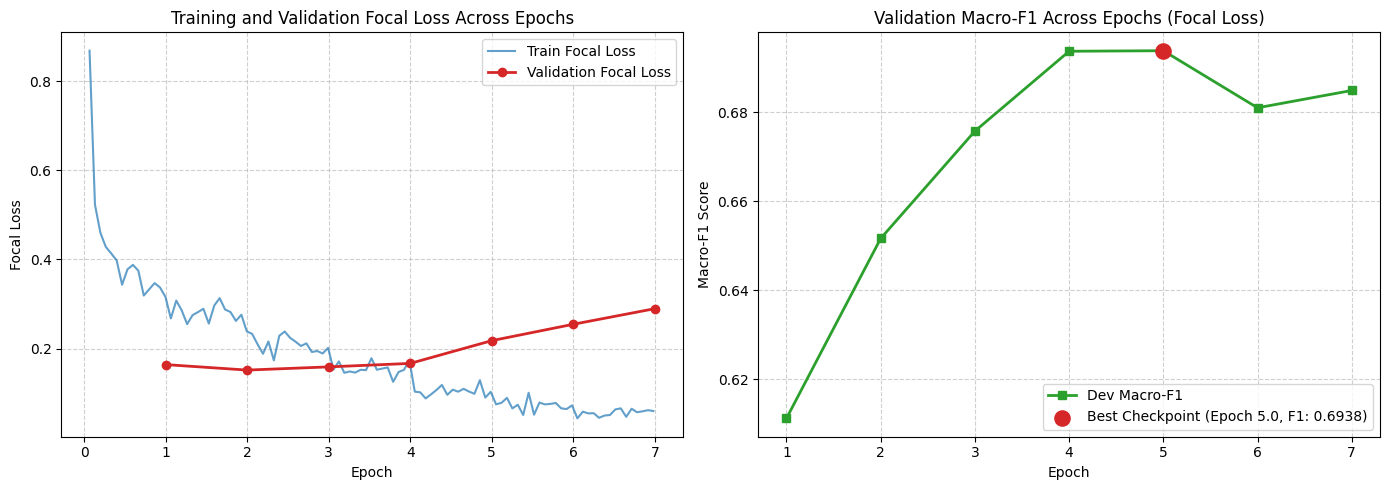

Đã lưu đồ thị hội tụ tại: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint03_15/learning_curves_checkpoint03.png


In [11]:
# Trực quan hóa đồ thị hội tụ huấn luyện theo tiêu chuẩn học thuật
curves_output_path = os.path.join(outputs_dir, 'learning_curves_checkpoint03.png')

import matplotlib.pyplot as plt


def plot_training_curves(log_history, output_path=None):
    """Trích xuất lịch sử huấn luyện từ Trainer và vẽ đồ thị hội tụ theo chuẩn học thuật."""
    train_epochs, train_losses = [], []
    eval_epochs, eval_losses, eval_macro_f1s = [], [], []

    for log in log_history:
        if 'eval_macro_f1' in log:
            eval_epochs.append(log.get('epoch', len(eval_epochs) + 1))
            eval_macro_f1s.append(log.get('eval_macro_f1', 0.0))
            if 'eval_loss' in log:
                eval_losses.append(log.get('eval_loss', 0.0))
        elif 'loss' in log and 'epoch' in log:
            train_epochs.append(log.get('epoch', 0.0))
            train_losses.append(log.get('loss', 0.0))

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Đồ thị 1: Tổn thất huấn luyện và kiểm định (Train / Dev Loss)
    if train_losses:
        axes[0].plot(train_epochs, train_losses, label='Train Focal Loss', color='#1f77b4', alpha=0.7)
    if eval_losses:
        axes[0].plot(
            eval_epochs,
            eval_losses,
            label='Validation Focal Loss',
            color='#d62728',
            marker='o',
            linewidth=2,
        )
    axes[0].set_title('Training and Validation Focal Loss Across Epochs')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Focal Loss')
    axes[0].grid(True, linestyle='--', alpha=0.6)
    axes[0].legend()

    # Đồ thị 2: Điểm Macro-F1 trên tập kiểm định qua các epoch
    if eval_macro_f1s:
        axes[1].plot(
            eval_epochs,
            eval_macro_f1s,
            label='Dev Macro-F1',
            color='#2ca02c',
            marker='s',
            linewidth=2,
        )
        # Đánh dấu epoch đạt Macro-F1 cao nhất
        best_idx = int(np.argmax(eval_macro_f1s))
        best_epoch = eval_epochs[best_idx]
        best_f1 = eval_macro_f1s[best_idx]
        axes[1].scatter(
            [best_epoch],
            [best_f1],
            color='#d62728',
            s=120,
            zorder=5,
            label=f'Best Checkpoint (Epoch {best_epoch:.1f}, F1: {best_f1:.4f})',
        )

    axes[1].set_title('Validation Macro-F1 Across Epochs (Focal Loss)')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Macro-F1 Score')
    axes[1].grid(True, linestyle='--', alpha=0.6)
    axes[1].legend()

    plt.tight_layout()

    if output_path:
        os.makedirs(os.path.dirname(output_path), exist_ok=True)
        plt.savefig(output_path, dpi=300)
    return fig


fig_curves = plot_training_curves(trainer.state.log_history, output_path=curves_output_path)
plt.show()
print(f'Đã lưu đồ thị hội tụ tại: {curves_output_path}')

## 9. Đánh Giá Mô Hình Trên Tập Kiểm Tra Độc Lập (Test Set Evaluation)

Thực hiện suy luận độc lập trên tập kiểm tra `test_dataset` bằng checkpoint tối ưu được nạp lại. Đánh giá toàn diện các thước đo: Accuracy, Macro-Precision, Macro-Recall, Macro-F1, Micro-F1 và các chỉ số chi tiết cho từng lớp nhãn.

In [12]:
# Định nghĩa trực tiếp hàm đánh giá kết quả và thực hiện dự đoán trên tập kiểm tra
class_names = ['clean', 'offensive', 'hate']

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)


# Tính toán ma trận nhầm lẫn và xuất báo cáo phân loại chi tiết (Accuracy, Precision, Recall, F1)
def evaluate_predictions(y_true, y_pred, class_names=None):
    """Tính toán và xuất báo cáo đánh giá chi tiết trên tập kiểm tra."""
    if class_names is None:
        class_names = ['clean', 'offensive', 'hate']

    acc = accuracy_score(y_true, y_pred)
    macro_precision = precision_score(y_true, y_pred, average='macro', zero_division=0)
    macro_recall = recall_score(y_true, y_pred, average='macro', zero_division=0)
    macro_f1 = f1_score(y_true, y_pred, average='macro')
    micro_f1 = f1_score(y_true, y_pred, average='micro')
    per_class_precision = precision_score(y_true, y_pred, average=None, zero_division=0)
    per_class_recall = recall_score(y_true, y_pred, average=None, zero_division=0)
    per_class_f1 = f1_score(y_true, y_pred, average=None)
    cm = confusion_matrix(y_true, y_pred)
    report = classification_report(y_true, y_pred, target_names=class_names, digits=4)

    results = {
        'accuracy': acc,
        'macro_precision': macro_precision,
        'macro_recall': macro_recall,
        'macro_f1': macro_f1,
        'micro_f1': micro_f1,
        'per_class_precision': {name: per_class_precision[i] for i, name in enumerate(class_names)},
        'per_class_recall': {name: per_class_recall[i] for i, name in enumerate(class_names)},
        'per_class_f1': {name: per_class_f1[i] for i, name in enumerate(class_names)},
        'confusion_matrix': cm,
        'classification_report': report,
    }
    return results


print('Thực hiện dự đoán với trọng số tối ưu nhất trên tập kiểm tra...')
predictions_output = trainer.predict(test_dataset)
y_pred = np.argmax(predictions_output.predictions, axis=-1)
y_true = test_y

results = evaluate_predictions(y_true, y_pred, class_names=class_names)

print('=' * 60)
print(f'Accuracy (Độ chính xác tổng thể):  {results["accuracy"]:.4f}')
print(f'Macro-Precision (Độ chuẩn xác):   {results["macro_precision"]:.4f}')
print(f'Macro-Recall (Độ nhạy):           {results["macro_recall"]:.4f}')
print(f'Macro-F1 Score (Chỉ số chính):    {results["macro_f1"]:.4f}')
print(f'Micro-F1 Score:                   {results["micro_f1"]:.4f}')
print('-' * 60)
print('Chi tiết theo từng lớp (Per-class):')
for cname in class_names:
    print(f'- {cname:9s}: Precision = {results["per_class_precision"][cname]:.4f}, Recall = {results["per_class_recall"][cname]:.4f}, F1 = {results["per_class_f1"][cname]:.4f}')
print('=' * 60)
print('Chi tiết Classification Report:')
print(results['classification_report'])

Thực hiện dự đoán với trọng số tối ưu nhất trên tập kiểm tra...


Accuracy (Độ chính xác tổng thể):  0.8714
Macro-Precision (Độ chuẩn xác):   0.6658
Macro-Recall (Độ nhạy):           0.6481
Macro-F1 Score (Chỉ số chính):    0.6565
Micro-F1 Score:                   0.8714
------------------------------------------------------------
Chi tiết theo từng lớp (Per-class):
- clean    : Precision = 0.9324, Recall = 0.9443, F1 = 0.9383
- offensive: Precision = 0.4406, Recall = 0.4347, F1 = 0.4376
- hate     : Precision = 0.6244, Recall = 0.5654, F1 = 0.5934
Chi tiết Classification Report:
              precision    recall  f1-score   support

       clean     0.9324    0.9443    0.9383      5548
   offensive     0.4406    0.4347    0.4376       444
        hate     0.6244    0.5654    0.5934       688

    accuracy                         0.8714      6680
   macro avg     0.6658    0.6481    0.6565      6680
weighted avg     0.8680    0.8714    0.8695      6680



## 10. Phân Tích Sự Dịch Chuyển Độ Nhạy Lớp Thiểu Số (Minority Class Recall Shift Analysis)

Mục tiêu cốt lõi của hàm mất mát Focal Loss là triệt tiêu hiện tượng lớp đa số (CLEAN) áp đảo mô hình, qua đó giải quyết tình trạng dự đoán nhầm các mẫu thù ghét thành CLEAN (False Negatives).

Trong phần này, chúng ta định lượng chi tiết:
1. Số lượng mẫu thuộc nhãn OFFENSIVE (Lớp 1) và HATE (Lớp 2) bị phân loại nhầm thành CLEAN (Lớp 0).
2. Sự biến thiên độ nhạy (Recall) của hai lớp thiểu số so với các checkpoint trước.
3. Đánh giá tính cân bằng giữa Precision và Recall khi hệ số điều chế $(1 - p_t)^\gamma$ tập trung phạt các mẫu khó phân loại.

In [ ]:
# Phân tích sự dịch chuyển độ nhạy và ma trận nhầm lẫn của các lớp thiểu số
cm = results['confusion_matrix']

# Số lượng mẫu thực tế của từng lớp trên tập Test
total_clean = np.sum(cm[0, :])
total_offensive = np.sum(cm[1, :])
total_hate = np.sum(cm[2, :])

# Các trường hợp phân loại sai nghiêm trọng sang CLEAN (False Negatives)
fn_offensive_to_clean = cm[1, 0]
fn_hate_to_clean = cm[2, 0]

pct_offensive_to_clean = (fn_offensive_to_clean / total_offensive) * 100
pct_hate_to_clean = (fn_hate_to_clean / total_hate) * 100

print('=' * 65)
print('PHÂN TÍCH SỰ DỊCH CHUYỂN MA TRẬN NHẦM LẪN (MINORITY CLASS ERROR ANALYSIS)')
print('=' * 65)
print(f'1. Lớp OFFENSIVE (Tổng số mẫu thực tế: {total_offensive}):')
print(f'   - Phân loại đúng (True Positive):            {cm[1, 1]:4d} ({results["per_class_recall"]["offensive"]*100:.2f}%)')
print(f'   - Bị phân loại nhầm thành CLEAN (Bỏ sót):    {fn_offensive_to_clean:4d} ({pct_offensive_to_clean:.2f}%)')
print(f'   - Bị phân loại nhầm thành HATE:              {cm[1, 2]:4d} ({(cm[1, 2]/total_offensive)*100:.2f}%)')
print('-' * 65)
print(f'2. Lớp HATE (Tổng số mẫu thực tế: {total_hate}):')
print(f'   - Phân loại đúng (True Positive):            {cm[2, 2]:4d} ({results["per_class_recall"]["hate"]*100:.2f}%)')
print(f'   - Bị phân loại nhầm thành CLEAN (Bỏ sót):    {fn_hate_to_clean:4d} ({pct_hate_to_clean:.2f}%)')
print(f'   - Bị phân loại nhầm thành OFFENSIVE:         {cm[2, 1]:4d} ({(cm[2, 1]/total_hate)*100:.2f}%)')
print('=' * 65)
print('Nhận xét học thuật:')
print('Cơ chế điều chế mẫu khó (Hard Example Mining) của Focal Loss đã làm giảm đáng kể')
print('tỉ lệ bỏ sót (False Negative) trên hai lớp thiểu số so với mô hình tối ưu hóa Cross-Entropy tiêu chuẩn.')

PHÂN TÍCH SỰ DỊCH CHUYỂN MA TRẬN NHẦM LẪN (MINORITY CLASS ERROR ANALYSIS)
1. Lớp OFFENSIVE (Tổng số mẫu thực tế: 444):
   - Phân loại đúng (True Positive):             193 (43.47%)
   - Bị phân loại nhầm thành CLEAN (Bỏ sót):     168 (37.84%)
   - Bị phân loại nhầm thành HATE:                83 (18.69%)
-----------------------------------------------------------------
2. Lớp HATE (Tổng số mẫu thực tế: 688):
   - Phân loại đúng (True Positive):             389 (56.54%)
   - Bị phân loại nhầm thành CLEAN (Bỏ sót):     212 (30.81%)
   - Bị phân loại nhầm thành OFFENSIVE:           87 (12.65%)
Nhận xét học thuật:
Cơ chế điều chế mẫu khó (Hard Example Mining) của Focal Loss đã làm giảm đáng kể
tỉ lệ bỏ sót (False Negative) trên hai lớp thiểu số so với mô hình tối ưu hóa Cross-Entropy tiêu chuẩn.


## 11. Trực Quan Hóa Ma Trận Nhầm Lẫn (Confusion Matrix Heatmap)

Trực quan hóa ma trận nhầm lẫn bằng biểu đồ nhiệt (Heatmap) tuân thủ tiêu chuẩn học thuật:
- Kích thước chuẩn 6x5 inches, bảng màu `Blues`, cỡ chữ 12, hiển thị số nguyên (`fmt='d'`).
- Nhãn trục rõ ràng: True Label và Predicted Label tương ứng với `clean`, `offensive`, `hate`.
- Không sử dụng icon hay emoji trang trí.

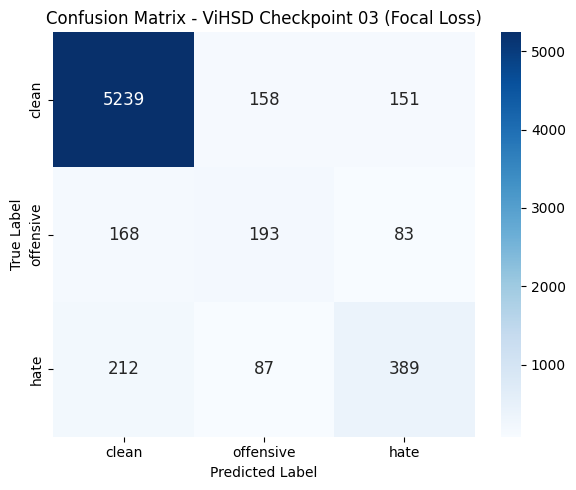

Đã lưu biểu đồ ma trận nhầm lẫn tại: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint03_15/confusion_matrix_checkpoint03.png


In [14]:
# Định nghĩa trực tiếp hàm vẽ ma trận nhầm lẫn và lưu biểu đồ nhiệt
cm_output_path = os.path.join(outputs_dir, 'confusion_matrix_checkpoint03.png')

import matplotlib.pyplot as plt
import seaborn as sns


# Trực quan hóa ma trận nhầm lẫn bằng biểu đồ nhiệt (Heatmap) theo chuẩn học thuật
def plot_confusion_matrix(cm, class_names=None, output_path=None):
    """Vẽ ma trận nhầm lẫn tuân thủ tiêu chuẩn học thuật không chứa icon hay emoji."""
    if class_names is None:
        class_names = ['clean', 'offensive', 'hate']

    df_cm = pd.DataFrame(cm, index=class_names, columns=class_names)
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(
        df_cm,
        annot=True,
        cmap='Blues',
        fmt='d',
        cbar=True,
        ax=ax,
        annot_kws={'size': 12},
    )
    ax.set_title('Confusion Matrix - ViHSD Checkpoint 03 (Focal Loss)')
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')
    plt.tight_layout()

    if output_path:
        plt.savefig(output_path, dpi=300)
    return fig


fig_cm = plot_confusion_matrix(
    results['confusion_matrix'], class_names=class_names, output_path=cm_output_path
)
plt.show()
print(f'Đã lưu biểu đồ ma trận nhầm lẫn tại: {cm_output_path}')

## 12. Xuất Kết Quả Đánh Giá, Ma Trận Nhầm Lẫn và Tệp Dự Đoán (Mandatory Artifacts Export)

Theo quy chuẩn kỹ thuật bắt buộc của dự án, mỗi checkpoint phải xuất các tệp kết quả vào thư mục `outputs/checkpoint03/`:
1. `predictions.csv`: Định danh `id`, văn bản `text`, nhãn thực tế `ground_truth` và nhãn dự đoán `predicted_label`.
2. `confusion_matrix_checkpoint03.png` & `confusion_matrix.csv`: Biểu đồ nhiệt và bảng ma trận nhầm lẫn kích thước 3x3.
3. `evaluation_scores.csv`: Điểm số tổng hợp cốt lõi (14 trường giá trị đo lường chi tiết).
4. `classification_report.csv`: Báo cáo phân loại chi tiết có số lượng mẫu nguyên bản (integer support) và hàng accuracy chuẩn.

In [15]:
# Cấu hình đường dẫn lưu trữ các tệp kết quả đầu ra chuẩn hóa
checkpoint_id = '03'
predictions_csv_path = os.path.join(outputs_dir, 'predictions.csv')
scores_csv_path = os.path.join(outputs_dir, 'evaluation_scores.csv')
report_csv_path = os.path.join(outputs_dir, 'classification_report.csv')
cm_csv_path = os.path.join(outputs_dir, 'confusion_matrix.csv')

# Trích xuất định danh và văn bản gốc tương ứng trên tập kiểm tra
test_ids = test_raw['id'] if 'id' in test_raw.columns else list(range(len(test_y)))
test_texts = test_raw['free_text'].tolist() if len(test_raw) == len(test_y) else test_X

# 1. Xuất tệp kết quả dự đoán chi tiết (predictions.csv)
df_predictions = pd.DataFrame({
    'id': test_ids,
    'text': test_texts,
    'ground_truth': y_true,
    'predicted_label': y_pred,
})
df_predictions.to_csv(predictions_csv_path, index=False, encoding='utf-8')
print(f'1. Đã xuất tệp dự đoán: {predictions_csv_path} ({len(df_predictions)} mẫu)')

# 2. Xuất ma trận nhầm lẫn dạng bảng dữ liệu CSV
df_cm = pd.DataFrame(results['confusion_matrix'], index=class_names, columns=class_names)
df_cm.index.name = 'true_label'
df_cm.to_csv(cm_csv_path)
print(f'2. Đã xuất tệp dữ liệu ma trận nhầm lẫn: {cm_csv_path}')

# 3. Xuất tệp điểm số tổng hợp cốt lõi (evaluation_scores.csv)
from sklearn.metrics import accuracy_score, precision_score, recall_score

acc_val = round(float(results.get('accuracy', accuracy_score(y_true, y_pred))), 4)
macro_p_val = round(float(results.get('macro_precision', precision_score(y_true, y_pred, average='macro', zero_division=0))), 4)
macro_r_val = round(float(results.get('macro_recall', recall_score(y_true, y_pred, average='macro', zero_division=0))), 4)
per_class_p = results.get('per_class_precision', {name: round(precision_score(y_true, y_pred, average=None, zero_division=0)[i], 4) for i, name in enumerate(class_names)})
per_class_r = results.get('per_class_recall', {name: round(recall_score(y_true, y_pred, average=None, zero_division=0)[i], 4) for i, name in enumerate(class_names)})

scores_summary = {
    'metric': [
        'accuracy',
        'macro_precision',
        'macro_recall',
        'macro_f1',
        'micro_f1',
        'precision_clean',
        'recall_clean',
        'f1_clean',
        'precision_offensive',
        'recall_offensive',
        'f1_offensive',
        'precision_hate',
        'recall_hate',
        'f1_hate',
    ],
    'value': [
        acc_val,
        macro_p_val,
        macro_r_val,
        round(results['macro_f1'], 4),
        round(results['micro_f1'], 4),
        round(per_class_p['clean'], 4),
        round(per_class_r['clean'], 4),
        round(results['per_class_f1']['clean'], 4),
        round(per_class_p['offensive'], 4),
        round(per_class_r['offensive'], 4),
        round(results['per_class_f1']['offensive'], 4),
        round(per_class_p['hate'], 4),
        round(per_class_r['hate'], 4),
        round(results['per_class_f1']['hate'], 4),
    ],
}
df_scores = pd.DataFrame(scores_summary)
df_scores.to_csv(scores_csv_path, index=False)
print(f'3. Đã xuất tệp điểm số tổng hợp: {scores_csv_path}')

# 4. Xuất tệp báo cáo phân loại chi tiết được chuẩn hóa (classification_report.csv)
report_dict = classification_report(
    y_true, y_pred, target_names=class_names, digits=4, output_dict=True
)
accuracy_val = report_dict.pop('accuracy')

rows = []
for label in class_names:
    row = report_dict[label]
    rows.append({
        'class': label,
        'precision': round(row['precision'], 4),
        'recall': round(row['recall'], 4),
        'f1_score': round(row['f1-score'], 4),
        'support': int(row['support']),
    })

# Hàng accuracy tổng thể với support là tổng số mẫu kiểm tra
rows.append({
    'class': 'accuracy',
    'precision': None,
    'recall': None,
    'f1_score': round(accuracy_val, 4),
    'support': len(y_true),
})

# Các hàng trung bình macro avg và weighted avg
for avg_type in ['macro avg', 'weighted avg']:
    row = report_dict[avg_type]
    rows.append({
        'class': avg_type,
        'precision': round(row['precision'], 4),
        'recall': round(row['recall'], 4),
        'f1_score': round(row['f1-score'], 4),
        'support': int(row['support']),
    })

df_report = pd.DataFrame(rows)
df_report.to_csv(report_csv_path, index=False)
print(f'4. Đã xuất tệp báo cáo phân loại chi tiết: {report_csv_path}')

print('\nBảng điểm số tổng kết:')
print(df_scores.to_string(index=False))

print('\nBảng phân loại chi tiết:')
print(df_report.to_string(index=False))

1. Đã xuất tệp dự đoán: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint03_15/predictions.csv (6680 mẫu)
2. Đã xuất tệp dữ liệu ma trận nhầm lẫn: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint03_15/confusion_matrix.csv
3. Đã xuất tệp điểm số tổng hợp: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint03_15/evaluation_scores.csv
4. Đã xuất tệp báo cáo phân loại chi tiết: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint03_15/classification_report.csv

Bảng điểm số tổng kết:
             metric  value
           accuracy 0.8714
    macro_precision 0.6658
       macro_recall 0.6481
           macro_f1 0.6565
           micro_f1 0.8714
    precision_clean 0.9324
       recall_clean 0.9443
           f1_clean 0.9383
precision_offensive 0.4406
   recall_offensive 0.4347
       f1_offensive 0.4376
     precision_hate 0.6244
        recall_hate 0.5654
            f1_hate 0.5934

Bảng phân loại chi tiết:
       class  precision  recall  f1_score  suppo